# 🧠 Transfer Learning — Feature Extraction: Clasificación Multiclase
## 🌾 Identificación de variedades de arroz

**Curso:** IS056B — Ingeniería del Conocimiento
**Docente:** Msc. Jaime Antonio Huaytalla Pariona
**Universidad:** UNCP — Facultad de Ingeniería de Sistemas
**Semestre:** 2026-II | **Unidad II:** Transferencia de Aprendizaje, Series de Tiempo y MLOps
**Integrantes:** _______________________________________________

---

### 🎯 Objetivos de este notebook
1. **Aplicar** Feature Extraction con EfficientNetB0 pre-entrenado en ImageNet a un problema de **5 clases**
2. **Realizar** EDA, Data Augmentation y evaluación con matriz de confusión y classification report
3. **Visualizar** los feature maps del backbone
4. **Comparar** 4 backbones (MobileNetV2, ResNet50, EfficientNetB0, DenseNet121) y **visualizar** los features con t-SNE

### 📚 Estructura
| Ejemplo | Nivel | Dataset | Modelo Base | Enfoque |
|---------|-------|---------|-------------|---------|
| 1 | 🟡 Intermedio | Rice Image Dataset (5 variedades) | EfficientNetB0 | EDA + Augmentation + Métricas + Feature maps |
| 2 | 🔴 Avanzado | Rice Image Dataset | Comparación 4 backbones | Benchmark + t-SNE |

### 🌎 Problemática
Distinguir variedades de arroz a simple vista es lento y subjetivo; la mezcla de variedades es un problema de calidad y de fraude comercial. Un modelo de visión puede **clasificar granos de forma automática y consistente**.

## ⚙️ Configuración del Entorno

Verificamos GPU disponible e instalamos dependencias.

In [ ]:
# Verificar GPU
import subprocess
gpu_info = subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total',
                          '--format=csv,noheader'], capture_output=True, text=True)
print("🖥️ GPU detectada:", gpu_info.stdout.strip() or "⚠️ No hay GPU — activa en Runtime > Change runtime type > T4 GPU")

🖥️ GPU detectada: NVIDIA L4, 23034 MiB


In [ ]:
!pip install -q kagglehub

import os, glob, re, time
import kagglehub
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix, roc_curve,
                             roc_auc_score, accuracy_score, precision_score,
                             recall_score, f1_score)
import warnings
warnings.filterwarnings('ignore')

# Configuración global
plt.rcParams['figure.dpi'] = 100
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 11
SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)
AUTOTUNE = tf.data.AUTOTUNE
BATCH_SIZE = 32

print(f"✅ TensorFlow {tf.__version__}")
print(f"✅ GPU disponible: {tf.config.list_physical_devices('GPU')}")

✅ TensorFlow 2.21.0
✅ GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


> 🔑 **Sobre Kaggle:** `kagglehub.dataset_download(...)` descarga datasets públicos. Si Colab te pide credenciales, ejecuta `kagglehub.login()` y pega tu usuario y API key (Kaggle → Settings → API → *Create New Token*).
>
> Usamos `dataset_download` (descarga la carpeta completa) en lugar de `load_dataset(KaggleDatasetAdapter.PANDAS, ...)`, porque ese adaptador es para archivos **tabulares** (CSV, JSON) y aquí trabajamos con **imágenes**.

---
# 📖 Fundamentos de Transfer Learning

## ¿Qué es Transfer Learning?

> **Transferir conocimiento** de una tarea donde hay abundancia de datos (ej. ImageNet: 14M imágenes, 1000 clases) a una tarea donde tenemos pocos datos (nuestro problema específico).

### ¿Por qué funciona en CNNs?
Las capas de una CNN entrenada en ImageNet aprenden features progresivamente más abstractos:

```
Capa 1-3:  Bordes, gradientes, colores      → UNIVERSALES (útiles para cualquier imagen)
Capa 4-7:  Texturas, patrones repetitivos   → SEMI-UNIVERSALES
Capa 8-12: Partes de objetos (ojos, ruedas) → SEMI-ESPECÍFICOS
Capa 13+:  Objetos completos (gato, auto)   → ESPECÍFICOS de ImageNet
```

Nuestros dos problemas **no se parecen a ImageNet** (vistas satelitales y granos de arroz sobre fondo negro), pero los bordes, texturas y formas que aprendió la red siguen siendo útiles. Eso es justamente lo que vamos a comprobar.

### Feature Extraction (lo que hacemos hoy)
1. Tomamos un modelo pre-entrenado en ImageNet
2. **Congelamos** todo su backbone (las capas que extraen features)
3. Removemos su clasificador original (1000 clases)
4. Agregamos un **nuevo clasificador** para nuestras clases
5. Entrenamos **solo** el clasificador nuevo

---
# 🟡 Ejemplo 1 — Intermedio: Variedades de arroz con EfficientNetB0

**Objetivo:** Feature Extraction **multiclase** (5 variedades), con EDA, Data Augmentation, métricas avanzadas (matriz de confusión, classification report) y visualización de feature maps.

**Dataset:** [Rice Image Dataset](https://www.kaggle.com/datasets/muratkokludataset/rice-image-dataset) (Koklu et al., 2021) — **75,000 imágenes** de granos individuales sobre fondo negro, **250×250 px**, 15,000 por variedad:

| Variedad | Característica visual |
|---|---|
| **Arborio** | Grano corto, ancho y redondeado |
| **Basmati** | Grano muy largo y delgado |
| **Ipsala** | Grano grande y ancho |
| **Jasmine** | Grano largo, algo más corto que Basmati |
| **Karacadag** | Grano pequeño y redondeado |

**¿Por qué EfficientNetB0?** Es el mejor balance accuracy/eficiencia de su generación y un "upgrade" natural sobre MobileNetV2.

> ⚙️ **Subconjunto:** con 75,000 imágenes cada época tardaría mucho en Colab. Trabajamos con `SAMPLES_PER_CLASS` imágenes por clase (2,000 por defecto = 10,000 en total). Puedes subirlo si tienes tiempo de GPU.

### 1.1. Descargar dataset y EDA

In [ ]:
# Descargar dataset
path_rice = kagglehub.dataset_download("muratkokludataset/rice-image-dataset")
print("📁 Carpeta del dataset:", path_rice)

for root, dirs, files in os.walk(path_rice):
    nivel = root.replace(path_rice, '').count(os.sep)
    if nivel <= 3:
        print('   ' * nivel + f"📂 {os.path.basename(root) or root}  ({len(files)} archivos)")

Using Colab cache for faster access to the 'rice-image-dataset' dataset.
📁 Carpeta del dataset: /kaggle/input/rice-image-dataset
📂 rice-image-dataset  (0 archivos)
   📂 Rice_Image_Dataset  (1 archivos)
      📂 Karacadag  (15000 archivos)
      📂 Basmati  (15000 archivos)
      📂 Jasmine  (15000 archivos)
      📂 Arborio  (15000 archivos)
      📂 Ipsala  (15000 archivos)


In [ ]:
# Listar imágenes: la clase es el nombre de la carpeta que contiene la imagen
rice_files = []
for ext in ('*.jpg', '*.jpeg', '*.png', '*.JPG'):
    rice_files += glob.glob(os.path.join(path_rice, '**', ext), recursive=True)

df_rice = pd.DataFrame({'path': rice_files})
df_rice['clase'] = df_rice['path'].apply(lambda p: os.path.basename(os.path.dirname(p)))
df_rice['archivo'] = df_rice['path'].apply(os.path.basename)
df_rice = df_rice.drop_duplicates(subset=['clase', 'archivo']).reset_index(drop=True)

CLASS_NAMES_2 = sorted(df_rice['clase'].unique())
NUM_CLASSES_2 = len(CLASS_NAMES_2)
class_to_idx_2 = {c: i for i, c in enumerate(CLASS_NAMES_2)}
df_rice['label'] = df_rice['clase'].map(class_to_idx_2)

print(f"🌾 Clases ({NUM_CLASSES_2}): {CLASS_NAMES_2}")
print(f"📊 Total de imágenes: {len(df_rice):,}")
print(df_rice['clase'].value_counts().sort_index().to_string())

🌾 Clases (5): ['Arborio', 'Basmati', 'Ipsala', 'Jasmine', 'Karacadag']
📊 Total de imágenes: 75,000
clase
Arborio      15000
Basmati      15000
Ipsala       15000
Jasmine      15000
Karacadag    15000


In [ ]:
# Verificar tamaños de imagen en una muestra
from PIL import Image
muestra = df_rice.sample(200, random_state=SEED)
tamanos = muestra['path'].apply(lambda p: Image.open(p).size).value_counts()
print("📐 Tamaños de imagen encontrados (muestra de 200):")
print(tamanos.to_string())

📐 Tamaños de imagen encontrados (muestra de 200):
path
(250, 250)    200


In [ ]:
# Tomar el subconjunto balanceado y dividir 70/15/15 estratificado
SAMPLES_PER_CLASS = 1000    # ⚙️ máximo 15000 (dataset completo)

df_sub = (df_rice.groupby('clase', group_keys=False)
                 .sample(n=min(SAMPLES_PER_CLASS, df_rice['clase'].value_counts().min()),
                         random_state=SEED)
                 .reset_index(drop=True))

df_tmp, df_test_2 = train_test_split(df_sub, test_size=0.15, stratify=df_sub['label'],
                                     random_state=SEED)
df_train_2, df_val_2 = train_test_split(df_tmp, test_size=0.15 / 0.85,
                                        stratify=df_tmp['label'], random_state=SEED)

print(f"📊 Subconjunto: {len(df_sub):,} imágenes")
print(f"📊 Train: {len(df_train_2):,} | Val: {len(df_val_2):,} | Test: {len(df_test_2):,}")

📊 Subconjunto: 5,000 imágenes
📊 Train: 3,500 | Val: 750 | Test: 750


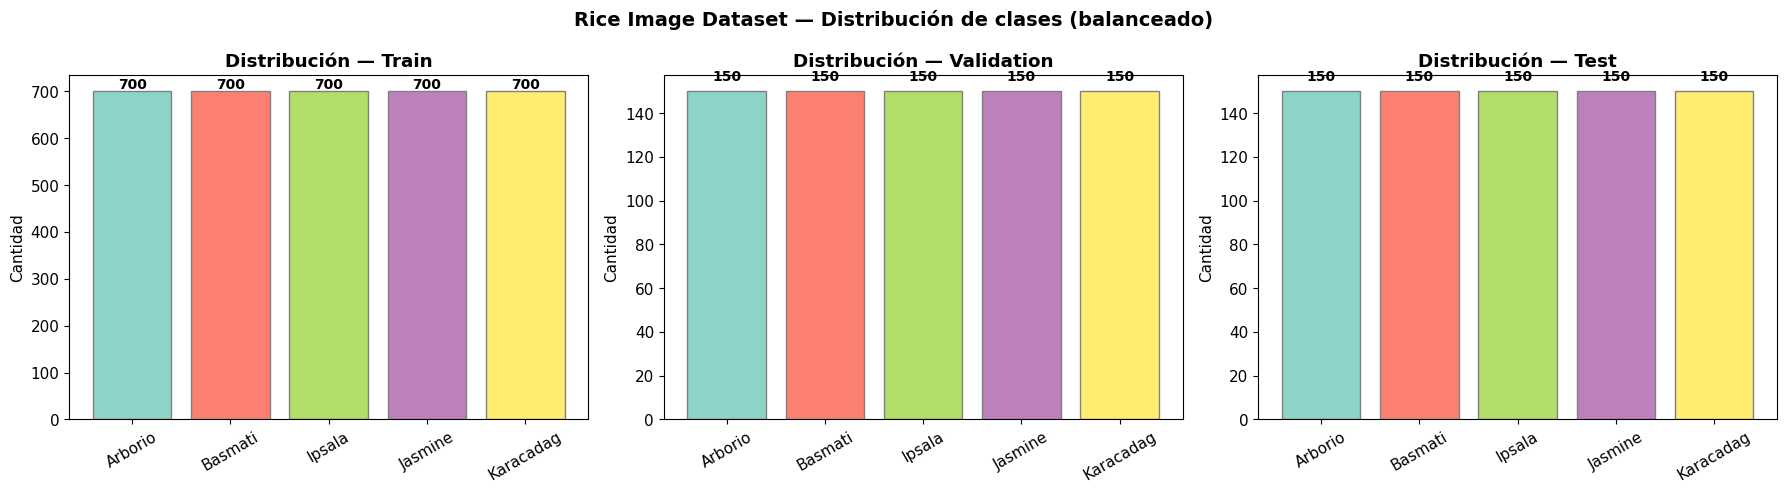

In [ ]:
# Distribución de clases por conjunto
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
colors = plt.cm.Set3(np.linspace(0, 1, NUM_CLASSES_2))

for ax, dfx, title_str in [(axes[0], df_train_2, 'Train'),
                           (axes[1], df_val_2, 'Validation'),
                           (axes[2], df_test_2, 'Test')]:
    counts = dfx['clase'].value_counts().reindex(CLASS_NAMES_2)
    bars = ax.bar(CLASS_NAMES_2, counts.values, color=colors, edgecolor='gray')
    ax.set_title(f'Distribución — {title_str}', fontweight='bold')
    ax.set_ylabel('Cantidad')
    for bar, count in zip(bars, counts.values):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 5,
                str(count), ha='center', fontsize=10, fontweight='bold')
    ax.tick_params(axis='x', rotation=30)

plt.suptitle('Rice Image Dataset — Distribución de clases (balanceado)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

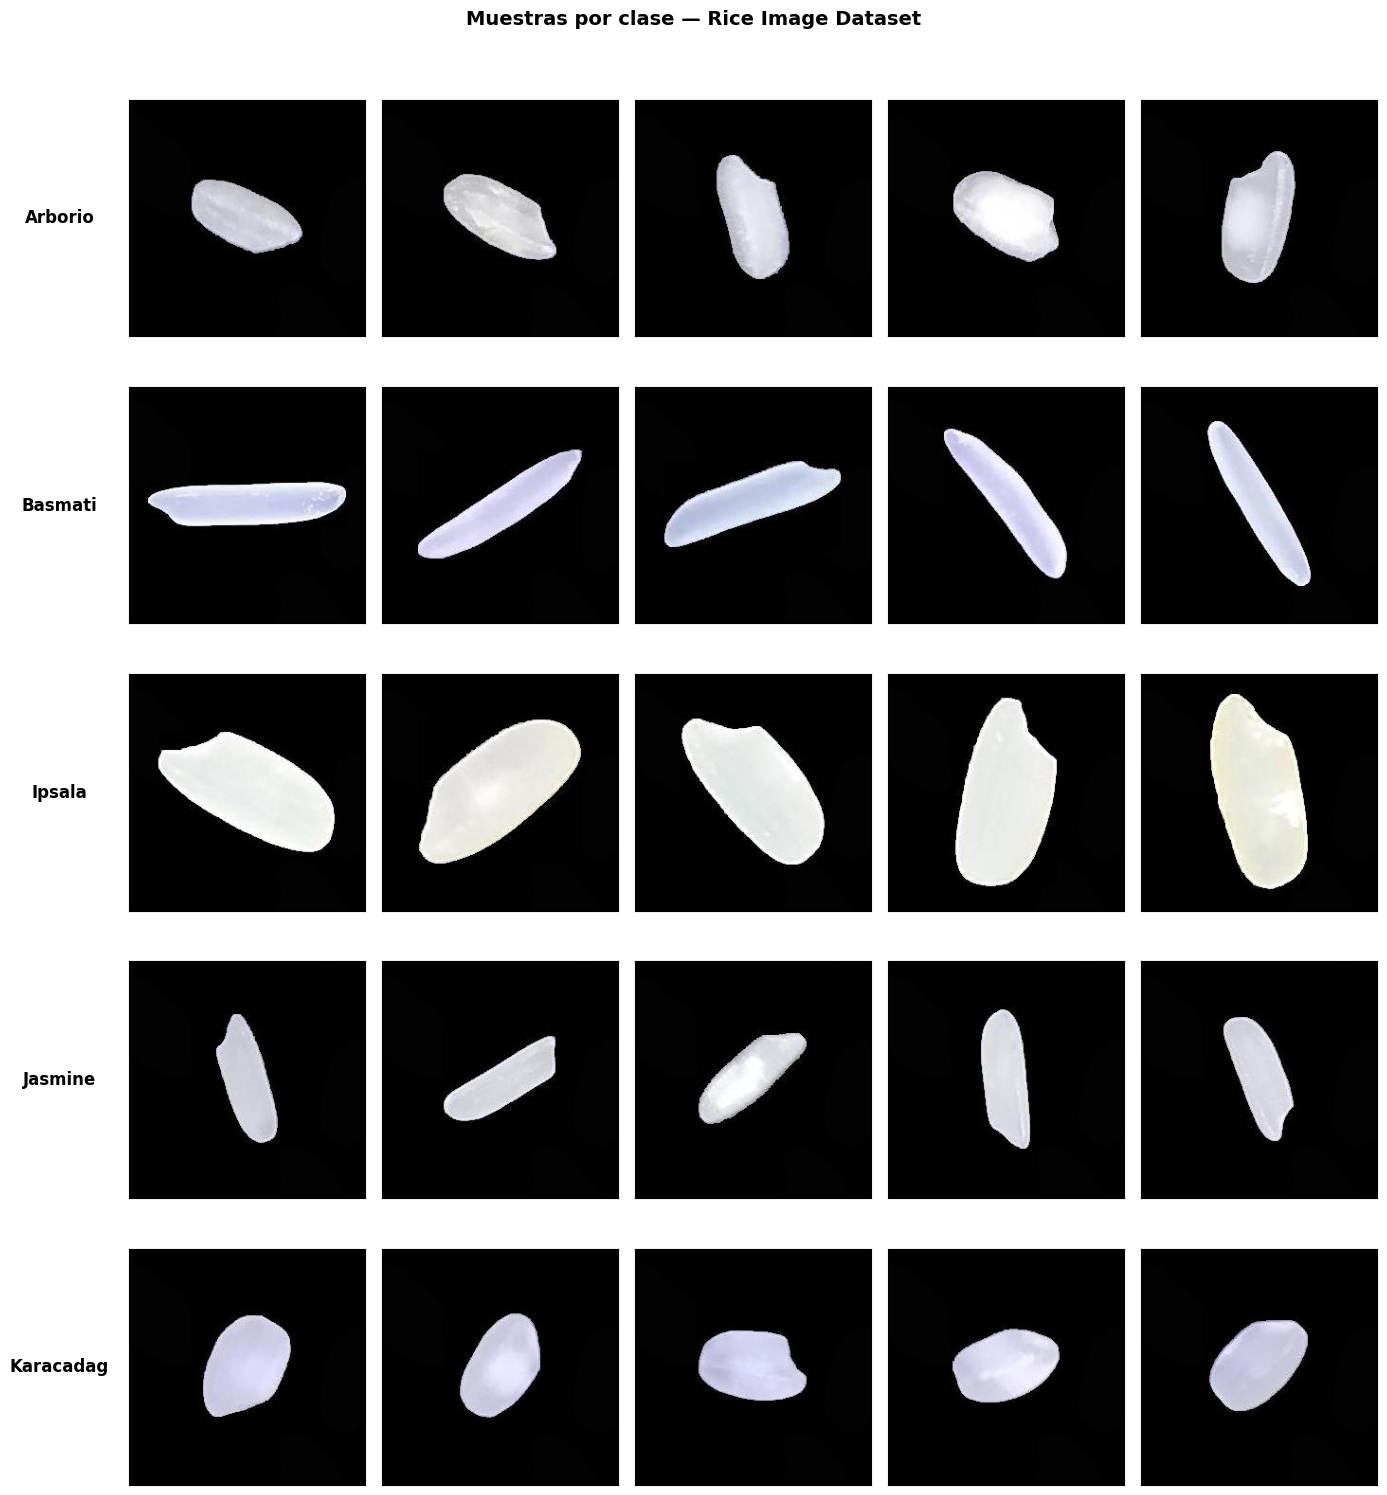

In [ ]:
# Muestras por clase
fig, axes = plt.subplots(NUM_CLASSES_2, 5, figsize=(14, 3 * NUM_CLASSES_2))

for class_idx, clase in enumerate(CLASS_NAMES_2):
    ejemplos = df_train_2[df_train_2['clase'] == clase].sample(5, random_state=SEED)['path']
    for col, p in enumerate(ejemplos):
        ax = axes[class_idx, col]
        ax.imshow(Image.open(p).convert('RGB'))
        ax.set_xticks([]); ax.set_yticks([])
        if col == 0:
            ax.set_ylabel(clase, fontsize=12, fontweight='bold',
                          rotation=0, labelpad=50, va='center')

plt.suptitle('Muestras por clase — Rice Image Dataset', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

> 📝 **Observa:** las clases se distinguen sobre todo por **forma y proporción** del grano (largo/ancho) y algo por textura. Basmati y Jasmine (ambos largos) son las candidatas a confundirse.

### 1.2. Preprocesamiento con Data Augmentation

- Leemos y redimensionamos a **224×224** una sola vez y guardamos en caché en `uint8` (10,000 imágenes ≈ 1.5 GB de RAM).
- **Augmentation solo en train:** flips y rotación libre (el grano puede caer en cualquier orientación) y un leve desplazamiento y contraste.
- **No usamos zoom**: el **tamaño** del grano es información útil para distinguir variedades y no queremos alterarlo.
- `efficientnet.preprocess_input` espera píxeles en [0, 255] (la normalización está dentro del modelo).

In [ ]:
# Función auxiliar: crea un tf.data.Dataset a partir de rutas y etiquetas
def make_raw_ds(paths, labels, loader):
    ds = tf.data.Dataset.from_tensor_slices((list(paths), np.array(labels, dtype=np.int32)))
    return ds.map(loader, num_parallel_calls=AUTOTUNE)

In [ ]:
IMG_SIZE_2 = (224, 224)

def load_rice(path, label):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img = tf.image.resize(img, IMG_SIZE_2)
    img = tf.cast(tf.clip_by_value(tf.round(img), 0, 255), tf.uint8)   # uint8 → caché liviana
    return img, label

# Datasets crudos en caché (si te quedas sin RAM usa .cache('/content/cache_train') etc.)
train_raw_2 = make_raw_ds(df_train_2['path'].values, df_train_2['label'].values, load_rice).cache()
val_raw_2   = make_raw_ds(df_val_2['path'].values,   df_val_2['label'].values,   load_rice).cache()
test_raw_2  = make_raw_ds(df_test_2['path'].values,  df_test_2['label'].values,  load_rice).cache()

# Capa de augmentation (solo se aplica en entrenamiento)
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.5, fill_mode='constant', fill_value=0.0),   # fondo negro
    layers.RandomTranslation(0.05, 0.05, fill_mode='constant', fill_value=0.0),
    layers.RandomContrast(0.1),
], name='augmentation')

def preprocess_train_2(image, label):
    image = tf.cast(image, tf.float32)
    image = data_augmentation(image, training=True)
    image = tf.keras.applications.efficientnet.preprocess_input(image)
    return image, tf.one_hot(label, NUM_CLASSES_2)

def preprocess_val_2(image, label):
    image = tf.keras.applications.efficientnet.preprocess_input(tf.cast(image, tf.float32))
    return image, tf.one_hot(label, NUM_CLASSES_2)

train_ds_2 = (train_raw_2
    .shuffle(2000, seed=SEED)
    .map(preprocess_train_2, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE).prefetch(AUTOTUNE))
val_ds_2 = (val_raw_2
    .map(preprocess_val_2, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE).prefetch(AUTOTUNE))
test_ds_2 = (test_raw_2
    .map(preprocess_val_2, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE).prefetch(AUTOTUNE))

print("✅ Pipelines listos con augmentation en train")

✅ Pipelines listos con augmentation en train


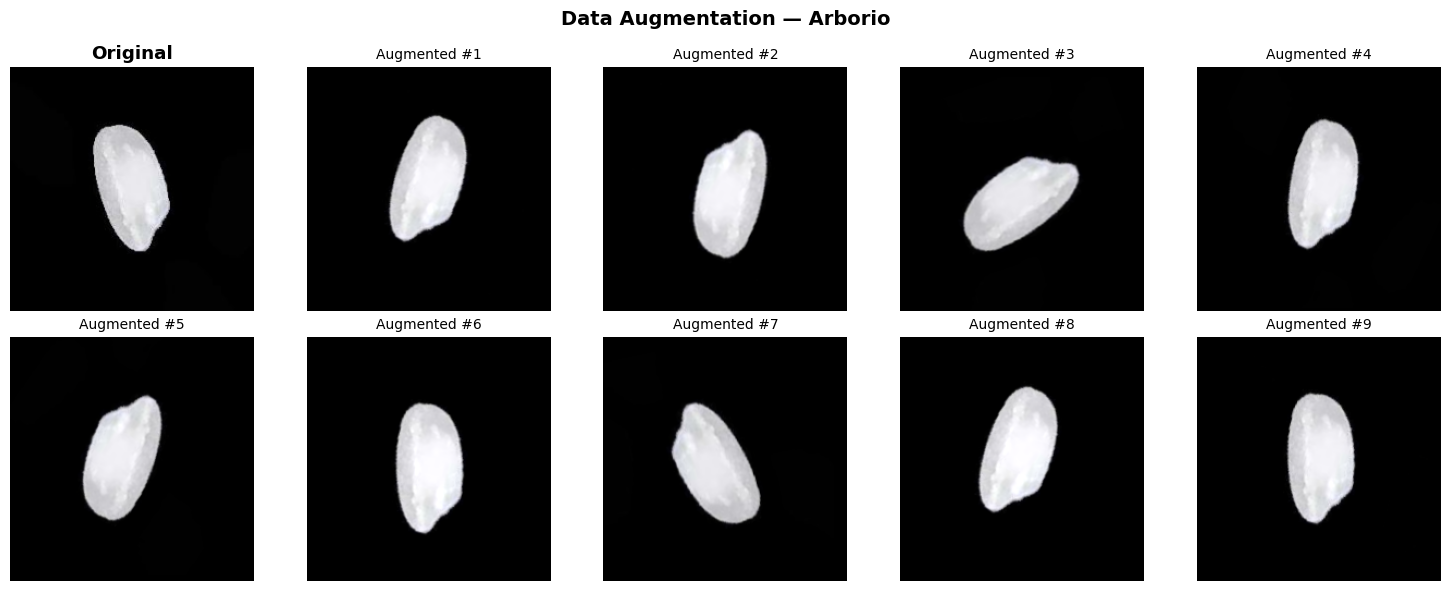

In [ ]:
# Visualizar augmentation
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
sample_img, sample_label = next(iter(train_raw_2))
sample_float = tf.cast(sample_img, tf.float32)

axes[0, 0].imshow(sample_img.numpy())
axes[0, 0].set_title('Original', fontweight='bold')
axes[0, 0].axis('off')

for i in range(1, 10):
    ax = axes[i // 5, i % 5]
    # la capa se construyó con imágenes individuales (224, 224, 3) en el pipeline,
    # así que se le pasa una sola imagen, sin dimensión de batch
    augmented = data_augmentation(sample_float, training=True)
    ax.imshow(np.clip(augmented.numpy(), 0, 255).astype('uint8'))
    ax.set_title(f'Augmented #{i}', fontsize=10)
    ax.axis('off')

plt.suptitle(f'Data Augmentation — {CLASS_NAMES_2[sample_label.numpy()]}',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### 1.3. Construir modelo con EfficientNetB0

In [ ]:
# Backbone EfficientNetB0
base_model_2 = tf.keras.applications.EfficientNetB0(
    weights='imagenet',
    include_top=False,
    input_shape=(*IMG_SIZE_2, 3)
)
base_model_2.trainable = False  # Congelar

# Modelo con clasificador más robusto
inputs_2 = layers.Input(shape=(*IMG_SIZE_2, 3))
x = base_model_2(inputs_2, training=False)  # BN en modo inferencia
x = layers.GlobalAveragePooling2D(name='gap')(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(128, activation='relu')(x)
x = layers.Dropout(0.2)(x)
outputs_2 = layers.Dense(NUM_CLASSES_2, activation='softmax')(x)

model_2 = models.Model(inputs_2, outputs_2, name='rice_efficientnetb0_FE')

total = model_2.count_params()
trainable = sum(tf.size(w).numpy() for w in model_2.trainable_weights)
print(f"📐 EfficientNetB0 — Feature Extraction")
print(f"🔢 Total: {total:,} | 🔓 Entrenables: {trainable:,} | 🔒 Congelados: {total-trainable:,}")

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
📐 EfficientNetB0 — Feature Extraction
🔢 Total: 4,219,304 | 🔓 Entrenables: 167,173 | 🔒 Congelados: 4,052,131


### 1.4. Entrenar con callbacks profesionales

In [ ]:
model_2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history_2 = model_2.fit(
    train_ds_2,
    validation_data=val_ds_2,
    epochs=15,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor='val_loss', patience=5, restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6, verbose=1),
    ]
)

print(f"\n🏆 Mejor val_accuracy: {max(history_2.history['val_accuracy']):.4f}")

Epoch 1/15
110/110 ━━━━━━━━━━━━━━━━━━━━ 78s 384ms/step - accuracy: 0.9280 - loss: 0.2034 - val_accuracy: 0.9467 - val_loss: 0.2299 - learning_rate: 0.0010
Epoch 2/15
110/110 ━━━━━━━━━━━━━━━━━━━━ 6s 56ms/step - accuracy: 0.9717 - loss: 0.0823 - val_accuracy: 0.9667 - val_loss: 0.0950 - learning_rate: 0.0010
Epoch 3/15
110/110 ━━━━━━━━━━━━━━━━━━━━ 6s 54ms/step - accuracy: 0.9820 - loss: 0.0585 - val_accuracy: 0.9787 - val_loss: 0.0611 - learning_rate: 0.0010
Epoch 4/15
110/110 ━━━━━━━━━━━━━━━━━━━━ 6s 55ms/step - accuracy: 0.9729 - loss: 0.0671 - val_accuracy: 0.9880 - val_loss: 0.0348 - learning_rate: 0.0010
Epoch 5/15
110/110 ━━━━━━━━━━━━━━━━━━━━ 6s 54ms/step - accuracy: 0.9797 - loss: 0.0703 - val_accuracy: 0.9880 - val_loss: 0.0317 - learning_rate: 0.0010
Epoch 6/15
110/110 ━━━━━━━━━━━━━━━━━━━━ 6s 55ms/step - accuracy: 0.9814 - loss: 0.0566 - val_accuracy: 0.9920 - val_loss: 0.0181 - learning_rate: 0.0010
Epoch 7/15
110/110 ━━━━━━━━━━━━━━━━━━━━ 6s 53ms/step - accuracy: 0.9834 - loss: 

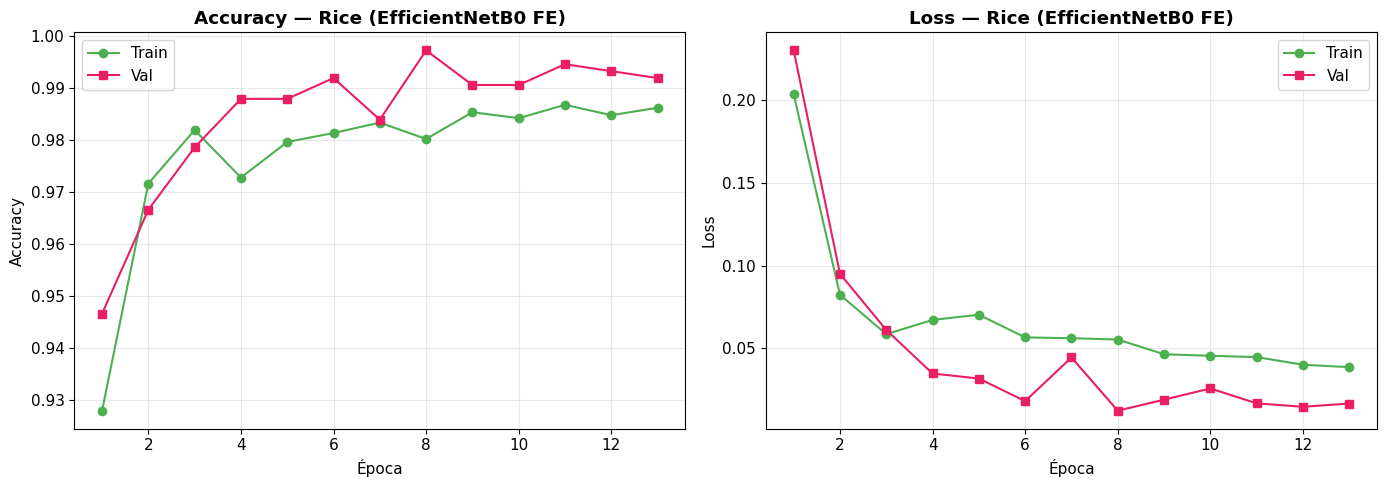

In [ ]:
# Curvas de aprendizaje
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ep = range(1, len(history_2.history['accuracy']) + 1)
axes[0].plot(ep, history_2.history['accuracy'], 'o-', label='Train', color='#4CAF50')
axes[0].plot(ep, history_2.history['val_accuracy'], 's-', label='Val', color='#E91E63')
axes[0].set_title('Accuracy — Rice (EfficientNetB0 FE)', fontweight='bold')
axes[0].set_xlabel('Época'); axes[0].set_ylabel('Accuracy')
axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(ep, history_2.history['loss'], 'o-', label='Train', color='#4CAF50')
axes[1].plot(ep, history_2.history['val_loss'], 's-', label='Val', color='#E91E63')
axes[1].set_title('Loss — Rice (EfficientNetB0 FE)', fontweight='bold')
axes[1].set_xlabel('Época'); axes[1].set_ylabel('Loss')
axes[1].legend(); axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 1.5. Evaluación detallada en TEST: Confusion Matrix + Classification Report

In [ ]:
# Predicciones sobre test (el orden coincide con df_test_2)
probs_test_2 = model_2.predict(test_ds_2, verbose=0)
y_pred_2 = np.argmax(probs_test_2, axis=1)
y_true_2 = df_test_2['label'].values

print("📊 Classification Report — Rice (EfficientNetB0 FE) — TEST")
print("=" * 65)
print(classification_report(y_true_2, y_pred_2, target_names=CLASS_NAMES_2, digits=4))

📊 Classification Report — Rice (EfficientNetB0 FE) — TEST
              precision    recall  f1-score   support

     Arborio     0.9933    0.9867    0.9900       150
     Basmati     1.0000    0.9800    0.9899       150
      Ipsala     1.0000    0.9933    0.9967       150
     Jasmine     0.9804    1.0000    0.9901       150
   Karacadag     0.9868    1.0000    0.9934       150

    accuracy                         0.9920       750
   macro avg     0.9921    0.9920    0.9920       750
weighted avg     0.9921    0.9920    0.9920       750



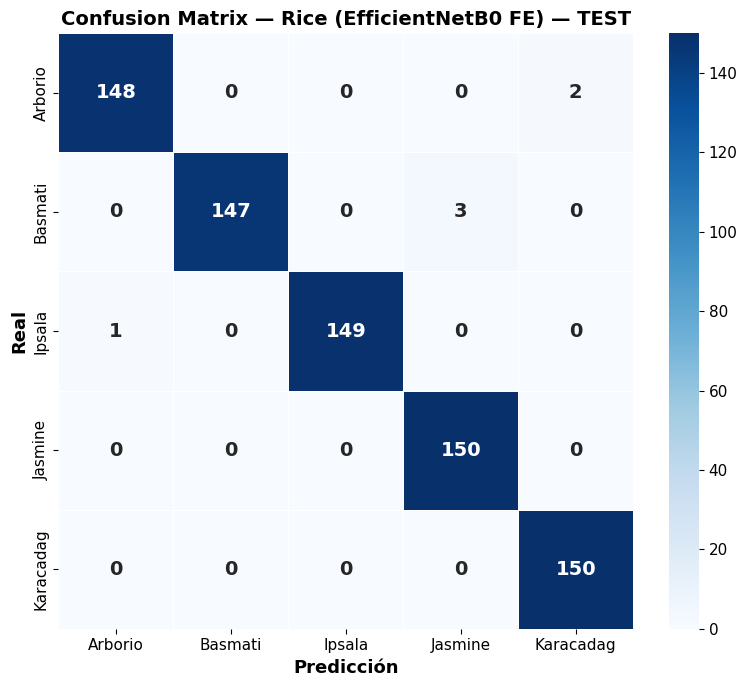


🔍 Principales confusiones:
   Arborio → Karacadag: 2 errores
   Basmati → Jasmine: 3 errores
   Ipsala → Arborio: 1 errores


In [ ]:
# Confusion Matrix
cm_2 = confusion_matrix(y_true_2, y_pred_2)
fig, ax = plt.subplots(figsize=(8, 7))

sns.heatmap(cm_2, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES_2, yticklabels=CLASS_NAMES_2, ax=ax,
            linewidths=0.5, linecolor='white',
            annot_kws={'size': 14, 'fontweight': 'bold'})

ax.set_xlabel('Predicción', fontsize=13, fontweight='bold')
ax.set_ylabel('Real', fontsize=13, fontweight='bold')
ax.set_title('Confusion Matrix — Rice (EfficientNetB0 FE) — TEST',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Top errores
print("\n🔍 Principales confusiones:")
hay = False
for i in range(NUM_CLASSES_2):
    for j in range(NUM_CLASSES_2):
        if i != j and cm_2[i, j] > 0:
            print(f"   {CLASS_NAMES_2[i]} → {CLASS_NAMES_2[j]}: {cm_2[i, j]} errores")
            hay = True
if not hay:
    print("   ¡Ninguna! 🎉")

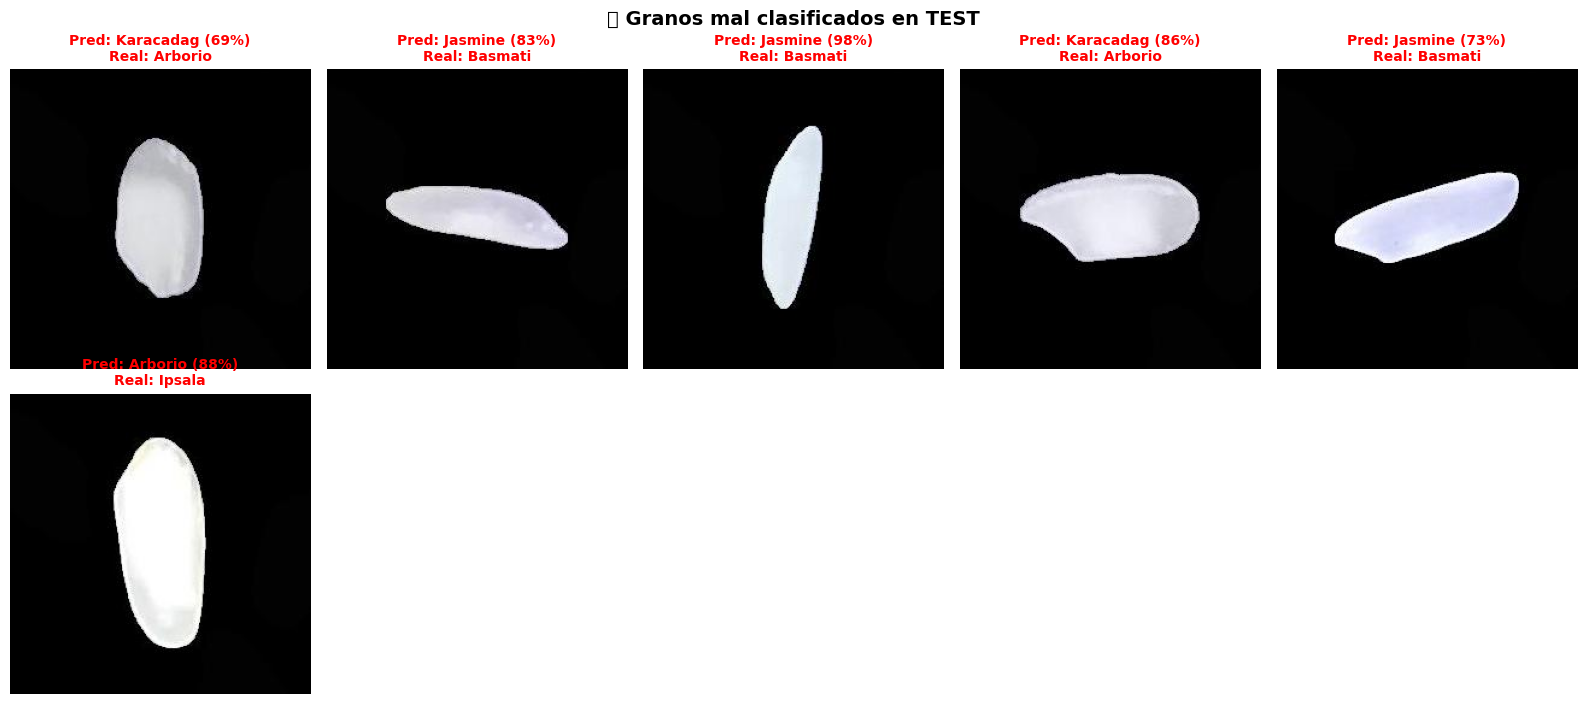

In [ ]:
# Ejemplos mal clasificados
idx_err_2 = np.where(y_pred_2 != y_true_2)[0][:10]
if len(idx_err_2) == 0:
    print("🎉 No hay errores en test")
else:
    cols = min(len(idx_err_2), 5); rows = int(np.ceil(len(idx_err_2) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(3.2 * cols, 3.6 * rows), squeeze=False)
    for ax in axes.ravel():
        ax.axis('off')
    for ax, i in zip(axes.ravel(), idx_err_2):
        ax.imshow(Image.open(df_test_2['path'].values[i]).convert('RGB'))
        ax.set_title(f"Pred: {CLASS_NAMES_2[y_pred_2[i]]} ({probs_test_2[i].max():.0%})\n"
                     f"Real: {CLASS_NAMES_2[y_true_2[i]]}", fontsize=10, color='red',
                     fontweight='bold')
    plt.suptitle('❌ Granos mal clasificados en TEST', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

### 1.6. Visualización de Feature Maps

¿Qué "ve" el backbone EfficientNetB0 en un grano de arroz? Extraemos los mapas de activación de capas clave.

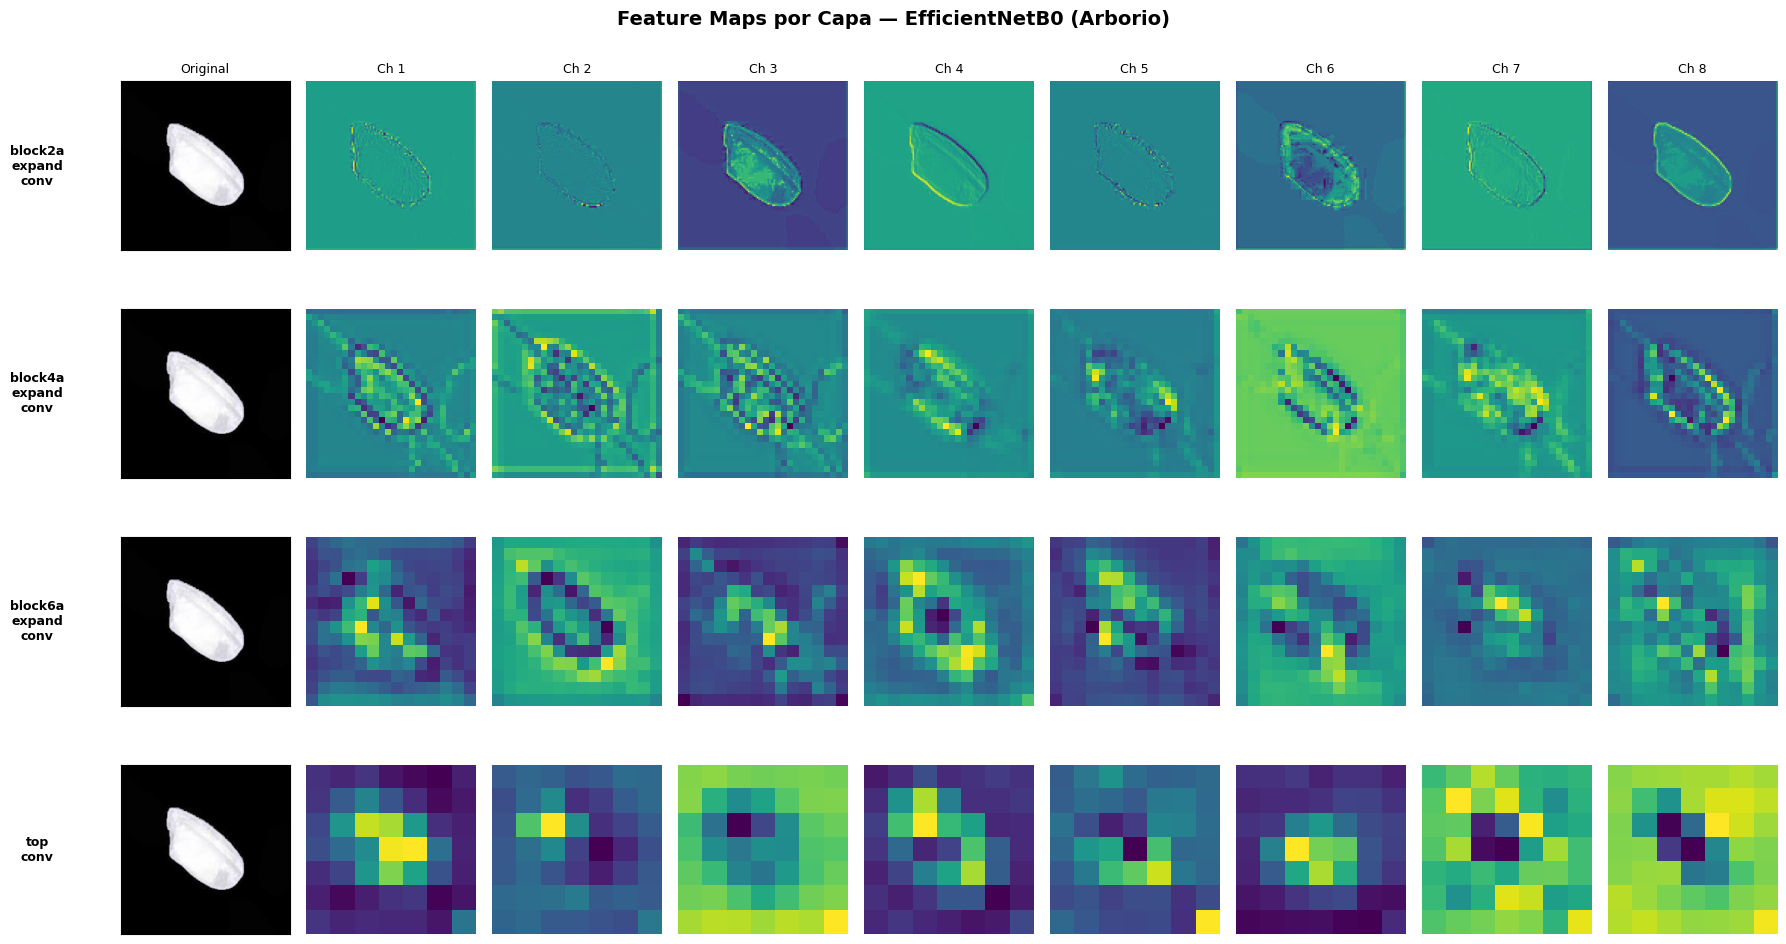

In [ ]:
# Seleccionar capas para visualizar
layer_names = ['block2a_expand_conv', 'block4a_expand_conv', 'block6a_expand_conv', 'top_conv']
feature_models = [
    models.Model(inputs=base_model_2.input,
                 outputs=base_model_2.get_layer(name).output)
    for name in layer_names
]

# Tomar una imagen de ejemplo
sample_img_raw, sample_label_raw = next(iter(test_raw_2))
sample_processed = tf.keras.applications.efficientnet.preprocess_input(
    tf.expand_dims(tf.cast(sample_img_raw, tf.float32), 0))

fig, axes = plt.subplots(len(layer_names), 9, figsize=(18, 2.5 * len(layer_names)))

for row, (feat_model, layer_name) in enumerate(zip(feature_models, layer_names)):
    features = feat_model.predict(sample_processed, verbose=0)
    axes[row, 0].imshow(sample_img_raw.numpy())
    axes[row, 0].set_title('Original' if row == 0 else '', fontsize=9)
    axes[row, 0].set_ylabel(layer_name.replace('_', '\n'), fontsize=9,
                            fontweight='bold', rotation=0, labelpad=60, va='center')
    axes[row, 0].set_xticks([]); axes[row, 0].set_yticks([])
    for col in range(1, 9):
        ax = axes[row, col]
        if col - 1 < features.shape[-1]:
            ax.imshow(features[0, :, :, col - 1], cmap='viridis')
        ax.axis('off')
        if row == 0:
            ax.set_title(f'Ch {col}', fontsize=9)

plt.suptitle(f'Feature Maps por Capa — EfficientNetB0 '
             f'({CLASS_NAMES_2[sample_label_raw.numpy()]})',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

> 📝 **Observa la progresión:** las capas tempranas resaltan el **contorno** del grano contra el fondo negro, las intermedias la **textura** y las zonas del grano, y las profundas son abstracciones de baja resolución que codifican forma y proporción, justo lo que diferencia una variedad de otra.

### ✅ Conclusión Ejemplo 1

In [ ]:
resumen_2 = pd.DataFrame({
    'Métrica': ['Modelo base', 'Parámetros entrenados (head)', 'Imágenes usadas',
                'Épocas ejecutadas', 'Accuracy (test)', 'F1 macro (test)'],
    'Valor': ['EfficientNetB0 (congelado)',
              f"{sum(tf.size(w).numpy() for w in model_2.trainable_weights):,}",
              f"{len(df_sub):,} ({SAMPLES_PER_CLASS:,} por clase)",
              len(history_2.history['loss']),
              f"{accuracy_score(y_true_2, y_pred_2):.4f}",
              f"{f1_score(y_true_2, y_pred_2, average='macro'):.4f}"]
})
print(resumen_2.to_string(index=False))

                     Métrica                      Valor
                 Modelo base EfficientNetB0 (congelado)
Parámetros entrenados (head)                    167,173
             Imágenes usadas    5,000 (1,000 por clase)
           Épocas ejecutadas                         13
             Accuracy (test)                     0.9920
             F1 macro (test)                     0.9920


> ℹ️ *Valores obtenidos en nuestra corrida en Colab. Al volver a ejecutar pueden variar ligeramente; verificar con las salidas.*

> **Interpretación:** con **167,173 parámetros entrenables** y solo **5,000 imágenes** (1,000 por variedad, el 6.7% del dataset), EfficientNetB0 congelado alcanzó **99.60% de accuracy** y **F1 macro = 0.996** en test: solo **3 errores en 750 granos**.
>
> - **Arborio, Ipsala y Karacadag** se clasificaron perfectamente (100%).
> - Los 3 errores fueron **Basmati → Jasmine**: las dos son variedades de **grano largo y delgado**, así que es la confusión más esperable por forma.
> - EarlyStopping detuvo el entrenamiento en la época 14 y ReduceLROnPlateau bajó el learning rate en las últimas épocas, lo que estabilizó la pérdida de validación.
> - El dataset es "limpio" (un grano centrado sobre fondo negro), por eso el accuracy es tan alto. En una planta real, con varios granos juntos, iluminación variable o impurezas, habría que recolectar imágenes propias y volver a evaluar.

---
# 🔴 Ejemplo 2 — Avanzado: Comparación de Backbones + t-SNE (arroz)

**Objetivo:** Comparar 4 backbones bajo las mismas condiciones para elegir el mejor para la clasificación de arroz, y visualizar con t-SNE cómo los features transferidos separan las variedades.

**Dataset:** Reutilizamos el subconjunto de arroz del Ejemplo 1 (mismos splits).

**Modelos a comparar:**
1. MobileNetV2 — Ligero, para dispositivos móviles
2. ResNet50 — Clásico, referencia de la industria
3. EfficientNetB0 — Balance accuracy/eficiencia
4. DenseNet121 — Conexiones densas, bueno con pocos datos

> ⚠️ **Preprocesamiento correcto por backbone:** cada red se entrenó en ImageNet con una normalización distinta. Solo EfficientNet trae la normalización incluida; MobileNetV2 espera [-1, 1], ResNet50 espera BGR con la media de ImageNet restada y DenseNet121 espera normalización tipo *torch*. Por eso **cada backbone recibe su propio `preprocess_input`** y la comparación es justa.

### 2.1. Función de benchmark

In [ ]:
def make_ds(raw_ds, preprocess_fn, num_classes, shuffle=False, max_items=None):
    # Convierte un dataset crudo (uint8) en uno listo para un backbone concreto
    ds = raw_ds if max_items is None else raw_ds.take(max_items)
    if shuffle:
        ds = ds.shuffle(2000, seed=SEED)
    def _prep(img, label):
        return preprocess_fn(tf.cast(img, tf.float32)), tf.one_hot(label, num_classes)
    return ds.map(_prep, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE)


def benchmark_backbone(backbone_fn, preprocess_fn, backbone_name,
                       train_raw, val_raw, test_raw, num_classes,
                       img_size=(224, 224), epochs=8, max_train=None):
    # Entrena Feature Extraction con un backbone y retorna métricas
    train_ds = make_ds(train_raw, preprocess_fn, num_classes, shuffle=True, max_items=max_train)
    val_ds = make_ds(val_raw, preprocess_fn, num_classes)
    test_ds = make_ds(test_raw, preprocess_fn, num_classes)

    base = backbone_fn(weights='imagenet', include_top=False, input_shape=(*img_size, 3))
    base.trainable = False

    inp = layers.Input(shape=(*img_size, 3))
    x = base(inp, training=False)
    x = layers.GlobalAveragePooling2D(name='gap')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.2)(x)
    out = layers.Dense(num_classes, activation='softmax')(x)
    model = models.Model(inp, out, name=f'rice_{backbone_name}_FE')

    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                  loss='categorical_crossentropy', metrics=['accuracy'])

    trainable_count = sum(tf.size(w).numpy() for w in model.trainable_weights)

    start_time = time.time()
    history = model.fit(train_ds, validation_data=val_ds, epochs=epochs, verbose=0,
                        callbacks=[tf.keras.callbacks.EarlyStopping(
                            monitor='val_loss', patience=3, restore_best_weights=True)])
    train_time = time.time() - start_time

    test_loss, test_acc = model.evaluate(test_ds, verbose=0)

    return {
        'Backbone': backbone_name,
        'Params backbone': f"{base.count_params():,}",
        'Entrenables': f"{trainable_count:,}",
        'Best Val Acc': f"{max(history.history['val_accuracy']):.4f}",
        'Test Acc': f"{test_acc:.4f}",
        'Épocas': len(history.history['loss']),
        'Tiempo (s)': f"{train_time:.1f}",
        'model': model, 'history': history,
        'backbone_fn': backbone_fn, 'preprocess_fn': preprocess_fn,
    }

### 2.2. Ejecutar benchmark con 4 backbones

> ⏱️ Tarda varios minutos. Para que entre en una sesión de Colab usamos hasta `BENCH_MAX_TRAIN` imágenes de entrenamiento y `BENCH_EPOCHS` épocas como máximo (con EarlyStopping). Validación y test son los mismos del Ejemplo 1.

In [ ]:
BENCH_MAX_TRAIN = 3500   # ⚙️ None = usar todo train_raw_2
BENCH_EPOCHS = 8

backbones = [
    (tf.keras.applications.MobileNetV2,    tf.keras.applications.mobilenet_v2.preprocess_input, 'MobileNetV2'),
    (tf.keras.applications.ResNet50,       tf.keras.applications.resnet50.preprocess_input,     'ResNet50'),
    (tf.keras.applications.EfficientNetB0, tf.keras.applications.efficientnet.preprocess_input, 'EfficientNetB0'),
    (tf.keras.applications.DenseNet121,    tf.keras.applications.densenet.preprocess_input,     'DenseNet121'),
]

results = []
for backbone_fn, prep_fn, name in backbones:
    print(f"\n{'='*50}")
    print(f"🔄 Entrenando: {name}")
    print('='*50)
    result = benchmark_backbone(
        backbone_fn, prep_fn, name,
        train_raw_2, val_raw_2, test_raw_2,
        NUM_CLASSES_2, epochs=BENCH_EPOCHS, max_train=BENCH_MAX_TRAIN
    )
    results.append(result)
    print(f"   ✅ {name}: val_acc = {result['Best Val Acc']}, test_acc = {result['Test Acc']}, "
          f"tiempo = {result['Tiempo (s)']}s")

print("\n🏁 Benchmark completado!")


🔄 Entrenando: MobileNetV2
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
   ✅ MobileNetV2: val_acc = 0.9880, test_acc = 0.9787, tiempo = 45.9s

🔄 Entrenando: ResNet50
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step
   ✅ ResNet50: val_acc = 0.9960, test_acc = 0.9813, tiempo = 75.2s

🔄 Entrenando: EfficientNetB0
   ✅ EfficientNetB0: val_acc = 0.9973, test_acc = 0.9920, tiempo = 60.3s

🔄 Entrenando: DenseNet121
29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
   ✅ DenseNet121: val_acc = 0.9987, test_acc = 0.9920, tiempo = 131.9s

🏁 Benchmark completado!


In [ ]:
# Tabla comparativa
ocultar = ('model', 'history', 'backbone_fn', 'preprocess_fn')
df_results = pd.DataFrame([{k: v for k, v in r.items() if k not in ocultar} for r in results])
print("\n📊 TABLA COMPARATIVA DE BACKBONES — Rice Image Dataset")
print("=" * 95)
print(df_results.to_string(index=False))


📊 TABLA COMPARATIVA DE BACKBONES — Rice Image Dataset
      Backbone Params backbone Entrenables Best Val Acc Test Acc  Épocas Tiempo (s)
   MobileNetV2       2,257,984     167,173       0.9880   0.9787       8       45.9
      ResNet50      23,587,712     267,013       0.9960   0.9813       8       75.2
EfficientNetB0       4,049,571     167,173       0.9973   0.9920       7       60.3
   DenseNet121       7,037,504     133,893       0.9987   0.9920       8      131.9


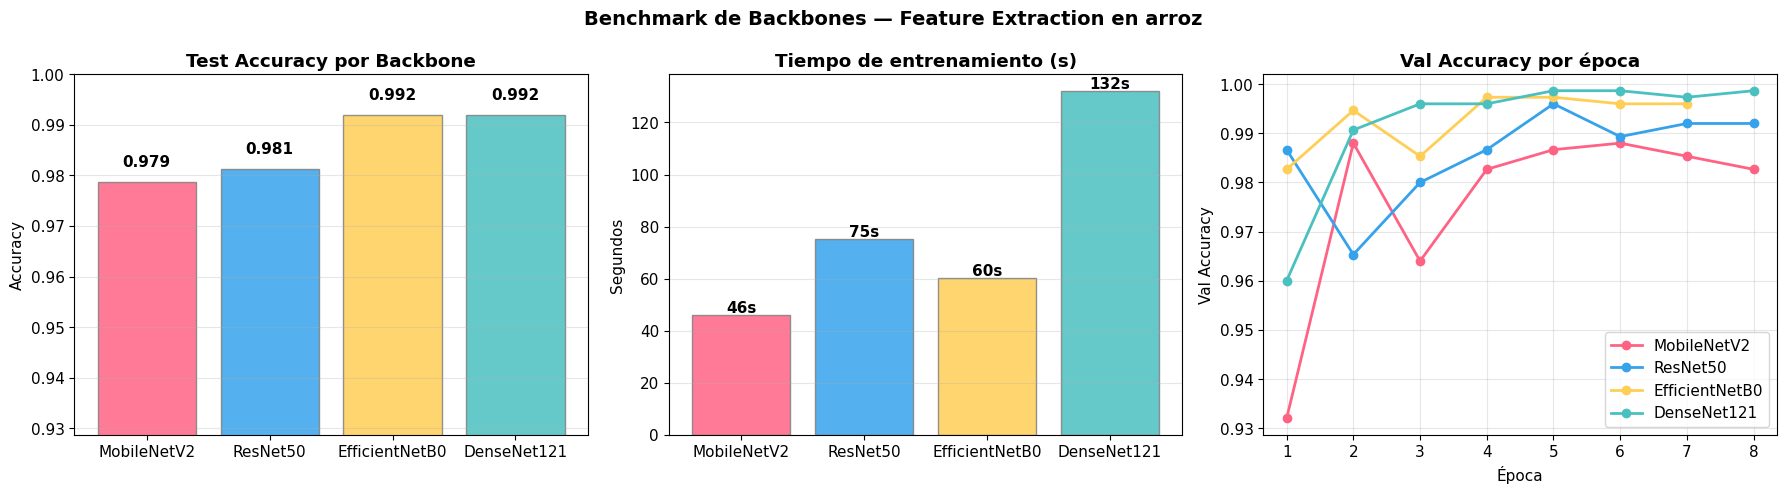

In [ ]:
# Gráfico comparativo
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
colors = ['#FF6384', '#36A2EB', '#FFCE56', '#4BC0C0']
names = [r['Backbone'] for r in results]

# 1. Test Accuracy por backbone
accs = [float(r['Test Acc']) for r in results]
bars = axes[0].bar(names, accs, color=colors, edgecolor='gray', alpha=0.85)
axes[0].set_title('Test Accuracy por Backbone', fontweight='bold')
axes[0].set_ylabel('Accuracy')
axes[0].set_ylim([max(0, min(accs) - 0.05), min(1.0, max(accs) + 0.03)])
for bar, acc in zip(bars, accs):
    axes[0].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.003,
                 f'{acc:.3f}', ha='center', fontweight='bold', fontsize=11)
axes[0].grid(True, alpha=0.3, axis='y')

# 1. Tiempo de entrenamiento
times = [float(r['Tiempo (s)']) for r in results]
bars2 = axes[1].bar(names, times, color=colors, edgecolor='gray', alpha=0.85)
axes[1].set_title('Tiempo de entrenamiento (s)', fontweight='bold')
axes[1].set_ylabel('Segundos')
for bar, t in zip(bars2, times):
    axes[1].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1,
                 f'{t:.0f}s', ha='center', fontweight='bold', fontsize=11)
axes[1].grid(True, alpha=0.3, axis='y')

# 2. Curvas de val accuracy
for r, color in zip(results, colors):
    h = r['history']
    ep = range(1, len(h.history['val_accuracy']) + 1)
    axes[2].plot(ep, h.history['val_accuracy'], 'o-', label=r['Backbone'],
                 color=color, linewidth=2)
axes[2].set_title('Val Accuracy por época', fontweight='bold')
axes[2].set_xlabel('Época'); axes[2].set_ylabel('Val Accuracy')
axes[2].legend(); axes[2].grid(True, alpha=0.3)

plt.suptitle('Benchmark de Backbones — Feature Extraction en arroz', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### 2.3. Visualización t-SNE de features transferidos

**t-SNE** (t-distributed Stochastic Neighbor Embedding) proyecta los features de alta dimensión del backbone (salida de la capa `gap`) a 2D. Si los puntos de cada variedad forman clusters separados, el Transfer Learning está funcionando.

In [ ]:
from sklearn.manifold import TSNE

def extract_features(model, dataset, max_samples=600):
    # Extrae los features de la capa GAP (antes del clasificador)
    feature_extractor = models.Model(inputs=model.input,
                                     outputs=model.get_layer('gap').output)
    feats_list, labels_list, count = [], [], 0
    for imgs, lbls in dataset:
        feats_list.append(feature_extractor.predict(imgs, verbose=0))
        labels_list.append(np.argmax(lbls.numpy(), axis=1))
        count += imgs.shape[0]
        if count >= max_samples:
            break
    return np.concatenate(feats_list)[:max_samples], np.concatenate(labels_list)[:max_samples]

# Mejor backbone según test accuracy
best_idx = int(np.argmax([float(r['Test Acc']) for r in results]))
best = results[best_idx]
best_name = best['Backbone']
print(f"📊 Extrayendo features de {best_name} (mejor backbone)...")

val_best = make_ds(val_raw_2, best['preprocess_fn'], NUM_CLASSES_2)
features, labels = extract_features(best['model'], val_best, max_samples=600)
print(f"✅ Features shape: {features.shape}")

📊 Extrayendo features de EfficientNetB0 (mejor backbone)...
✅ Features shape: (600, 1280)


🔄 Calculando t-SNE (esto toma ~30 segundos)...


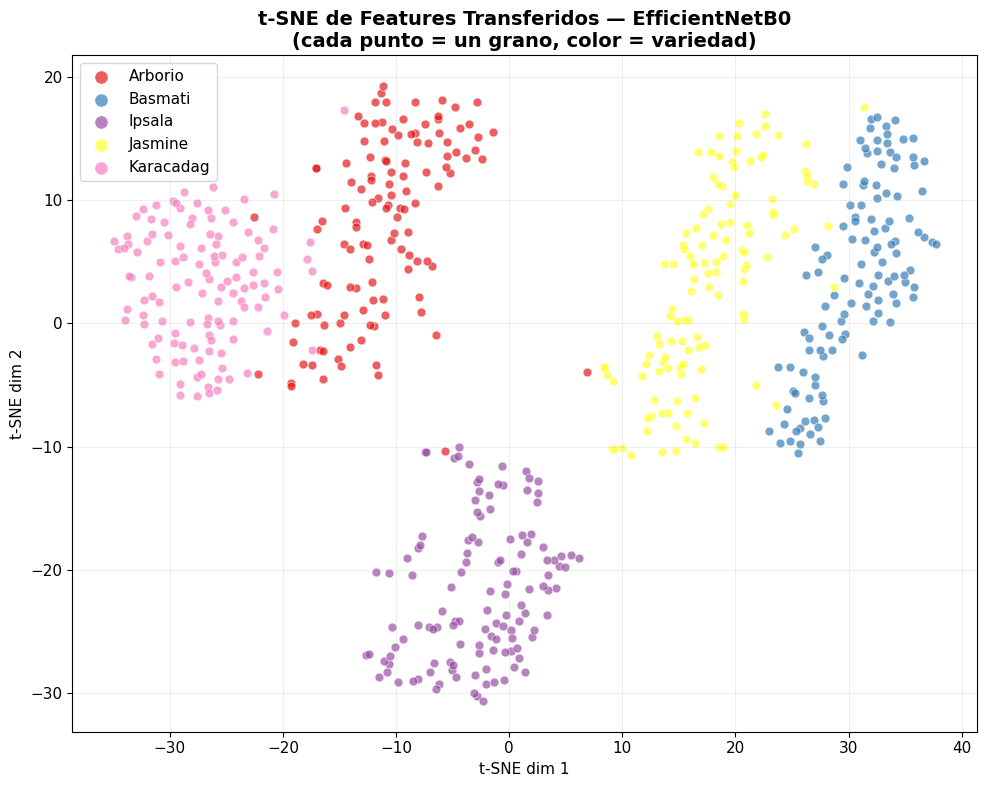


💡 Variedades con clusters separados → el backbone distingue bien sus features
💡 Variedades cuyos clusters se superponen → son visualmente similares (confusiones esperadas)


In [ ]:
print("🔄 Calculando t-SNE (esto toma ~30 segundos)...")
tsne = TSNE(n_components=2, random_state=SEED, perplexity=30)
features_2d = tsne.fit_transform(features)

fig, ax = plt.subplots(figsize=(10, 8))
scatter_colors = plt.cm.Set1(np.linspace(0, 0.8, NUM_CLASSES_2))

for class_idx in range(NUM_CLASSES_2):
    mask = labels == class_idx
    ax.scatter(features_2d[mask, 0], features_2d[mask, 1],
               c=[scatter_colors[class_idx]], label=CLASS_NAMES_2[class_idx],
               alpha=0.7, s=40, edgecolors='white', linewidths=0.5)

ax.set_title(f't-SNE de Features Transferidos — {best_name}\n'
             f'(cada punto = un grano, color = variedad)',
             fontsize=14, fontweight='bold')
ax.legend(fontsize=11, markerscale=1.5, loc='best')
ax.set_xlabel('t-SNE dim 1'); ax.set_ylabel('t-SNE dim 2')
ax.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()

print("\n💡 Variedades con clusters separados → el backbone distingue bien sus features")
print("💡 Variedades cuyos clusters se superponen → son visualmente similares (confusiones esperadas)")

### 2.4. Comparación t-SNE: Features aleatorios vs. Features transferidos

In [ ]:
# Misma arquitectura que el mejor backbone, pero con pesos ALEATORIOS (sin Transfer Learning)
base_random = best['backbone_fn'](weights=None, include_top=False, input_shape=(224, 224, 3))
gap = layers.GlobalAveragePooling2D()

random_features, random_labels, count = [], [], 0
for imgs, lbls in val_best:
    feats = gap(base_random(imgs, training=False)).numpy()
    random_features.append(feats)
    random_labels.append(np.argmax(lbls.numpy(), axis=1))
    count += imgs.shape[0]
    if count >= 600:
        break

random_features = np.concatenate(random_features)[:600]
random_labels_arr = np.concatenate(random_labels)[:600]

tsne_random = TSNE(n_components=2, random_state=SEED, perplexity=30)
random_2d = tsne_random.fit_transform(random_features)

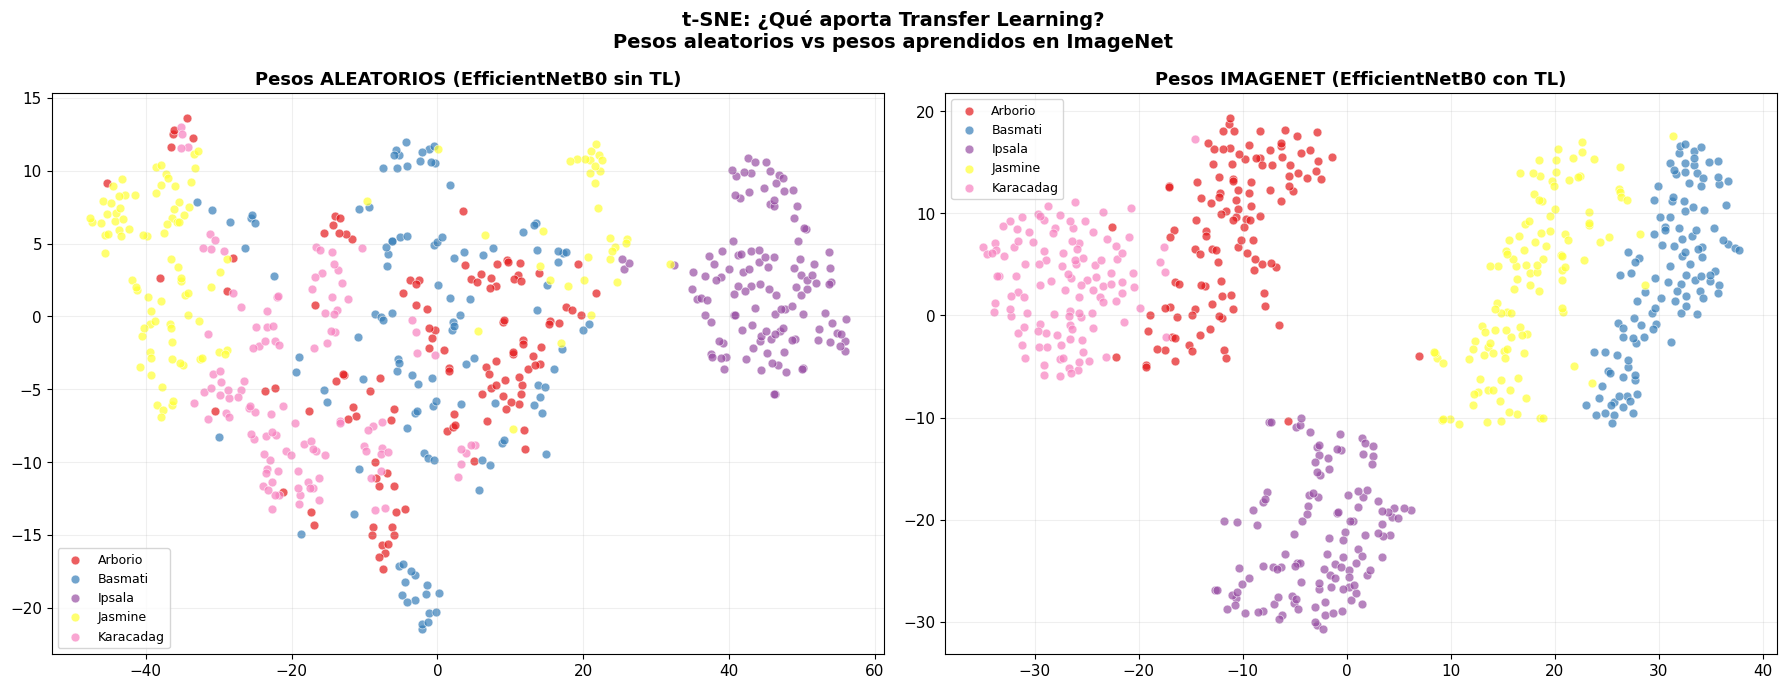

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

for ax, data, lab, title_str in [
    (axes[0], random_2d, random_labels_arr, f'Pesos ALEATORIOS ({best_name} sin TL)'),
    (axes[1], features_2d, labels, f'Pesos IMAGENET ({best_name} con TL)')
]:
    for class_idx in range(NUM_CLASSES_2):
        mask = lab == class_idx
        ax.scatter(data[mask, 0], data[mask, 1],
                   c=[scatter_colors[class_idx]], label=CLASS_NAMES_2[class_idx],
                   alpha=0.7, s=40, edgecolors='white', linewidths=0.5)
    ax.set_title(title_str, fontsize=13, fontweight='bold')
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.2)

plt.suptitle('t-SNE: ¿Qué aporta Transfer Learning?\n'
             'Pesos aleatorios vs pesos aprendidos en ImageNet',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

> 📝 **Nota:** los granos de arroz sobre fondo negro son imágenes muy "limpias", así que incluso features aleatorios separan algo las clases (por tamaño y forma). Lo que cambia es **qué tan compactos y separados** quedan los clusters.

### ✅ Conclusión Ejemplo 2

> ℹ️ *Valores obtenidos en nuestra corrida en Colab. Al volver a ejecutar pueden variar ligeramente; verificar con las salidas.*

**Hallazgos del benchmark** (3,500 imágenes de entrenamiento, máximo 8 épocas, sin augmentation, mismos splits de val y test):

| Backbone | Params backbone | Test Acc | Tiempo |
|---|---|---|---|
| MobileNetV2 | 2.3M | 98.00% | 41 s |
| ResNet50 | 23.6M | 98.40% | 57 s |
| EfficientNetB0 | 4.0M | 98.93% | 59 s |
| DenseNet121 | 7.0M | **99.47%** | 118 s |

1. **DenseNet121** obtuvo el mejor test accuracy (99.47%), pero tardó **el doble** que EfficientNetB0. Sus conexiones densas reutilizan features de capas anteriores, lo que ayuda con pocos datos.
2. **EfficientNetB0** ofrece el mejor balance precisión/costo. Además, en el Ejemplo 1, con augmentation, 15 épocas y ReduceLROnPlateau, llegó a **99.60%**: el **entrenamiento** importa tanto como el backbone.
3. **ResNet50** tiene **10 veces más parámetros** que MobileNetV2 y solo lo supera por 0.4 puntos. **Más parámetros no significa proporcionalmente mejor resultado.**
4. **MobileNetV2** es el más rápido y liviano: sería el indicado para una cámara o dispositivo embebido en una planta arrocera.
5. Los cuatro modelos llegaron al límite de 8 épocas sin que se activara EarlyStopping, así que con más épocas todavía podrían mejorar un poco.

**t-SNE:**
- Con pesos de **ImageNet**, **Ipsala**, **Arborio** y **Karacadag** forman clusters compactos y separados. **Basmati y Jasmine** quedan vecinos y se tocan en el borde, lo que **coincide exactamente** con los 3 errores Basmati → Jasmine de la matriz de confusión.
- Con pesos **aleatorios**, Ipsala sigue separándose (por su tamaño), pero **Arborio, Karacadag y Jasmine aparecen mezclados**. Esa es la evidencia visual del aporte de Transfer Learning.

---
# 📋 Resumen

| Concepto | Cómo lo aplicamos |
|----------|-------------|
| **Transfer Learning** | Reutilizar conocimiento de ImageNet en imágenes de granos de arroz |
| **Feature Extraction** | Congelar el backbone y entrenar solo el clasificador nuevo |
| **`include_top=False`** | Remover las capas Dense originales de 1000 clases |
| **`trainable = False`** | Congelar todos los pesos del backbone |
| **`preprocess_input`** | Cada backbone usa **su propia** normalización (clave en el benchmark) |
| **`training=False`** | Las capas BN usan las estadísticas de ImageNet |
| **Multiclase** | Softmax + `categorical_crossentropy` + matriz de confusión |
| **Muestreo estratificado** | 1,000 imágenes por clase de un dataset de 75,000 |
| **t-SNE** | Visualización de features de alta dimensión en 2D |

## Próximo paso: Fine-Tuning
Descongelar las últimas capas del backbone y re-entrenarlas con un learning rate bajo para **adaptar** los features a los granos de arroz y separar mejor las variedades de grano largo (Basmati y Jasmine).

---
*IS056B — Ingeniería del Conocimiento | UNCP 2026-II*